# Paper 17: End-to-End Object Detection with Transformers (DETR)
**Authors**: Nicolas Carion, Francisco Massa, Gabriel Synnaeve, Nicolas Usunier, Alexander Kirillov, Sergey Zagoruyko (Facebook AI Research, ECCV 2020)

---

## 1. The Historical Breaking Point: The Multi-Stage Anchor Pipeline
Prior to DETR, state-of-the-art object detection (Faster R-CNN, RetinaNet, YOLO) relied on complex, surrogate pipelines:
1. **Dense Prior Anchors**: Hand-crafting thousands of anchor boxes varying across arbitrary aspect ratios and scales.
2. **Anchor Assignment Heuristics**: Assigning positive/negative targets using ad-hoc IoU threshold rules.
3. **Non-Maximum Suppression (NMS)**: Post-processing to eliminate redundant, overlapping duplicate predictions.

These engineering crutches obscured detection as a pure machine learning problem and made hyperparameter tuning brittle.

## 2. The Thought Experiment: Detection as Direct Set Prediction
Object detection is fundamentally predicting a **set** of objects (class label + bounding box coordinates), invariant to ordering.

DETR simplifies detection into a streamlined, end-to-end framework:
- **CNN Backbone**: Extracts visual 2D feature maps from raw images.
- **Transformer Encoder-Decoder**: Encodes global image context and decodes fixed $N$ learned **object queries** into box coordinates and class probabilities simultaneously.
- **Bipartite Matching (Hungarian Algorithm)**: Optimally pairs each predicted box to exactly one ground-truth box using global minimum matching cost.
- **Set Prediction Loss**: Combines Cross-Entropy classification with Hungarian-matched L1 and Generalized IoU (GIoU) box regression.

$$\mathcal{L}_{\text{Hungarian}}(y, \hat{\sigma}) = \sum_{i=1}^N \left[ -\log \hat{p}_{\hat{\sigma}(i)}(c_i) + \mathbb{I}_{\{c_i \neq \varnothing\}} \left( \lambda_{\text{L1}} \|b_i - \hat{b}_{\hat{\sigma}(i)}\|_1 + \lambda_{\text{giou}} \mathcal{L}_{\text{giou}}(b_i, \hat{b}_{\hat{\sigma}(i)}) \right) \right]$$

In this notebook, you will build, explore, and verify:
1. Coordinate transformations (`cxcywh` $\leftrightarrow$ `xyxy`) and GIoU computation
2. 2D Sinusoidal Positional Embeddings
3. Bipartite Hungarian matching
4. The complete DETR architecture and `SetCriterion` loss

---
## Setup & Autoreload

In [1]:
%load_ext autoreload
%autoreload 2

import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import matplotlib.patches as patches

from model import (
    box_cxcywh_to_xyxy,
    box_xyxy_to_cxcywh,
    box_iou,
    generalized_box_iou,
    PositionEmbeddingSine,
    HungarianMatcher,
    SetCriterion,
    DETR,
)

print(f"PyTorch version: {torch.__version__}")

PyTorch version: 2.14.1+cpu


---
## 1. Box Representation & Generalized IoU (GIoU)
Transformers output normalized coordinates $(c_x, c_y, w, h) \in [0, 1]$. To compute overlap with ground truth, we convert to corners $(x_1, y_1, x_2, y_2)$.

Standard IoU provides **zero gradient** when two bounding boxes do not overlap. **GIoU** penalizes the distance between non-overlapping boxes by measuring the empty volume inside their smallest convex enclosing box $C$:
$$\text{GIoU} = \text{IoU} - \frac{|C \setminus (A \cup B)|}{|C|}$$
When disjoint, $\text{GIoU} \in [-1, 0)$, providing smooth, continuous gradients everywhere!

In [2]:
# Box conversion test
test_cxcywh = torch.tensor([[0.5, 0.5, 0.4, 0.6], [0.2, 0.3, 0.2, 0.2]])
test_xyxy = box_cxcywh_to_xyxy(test_cxcywh)
recovered_cxcywh = box_xyxy_to_cxcywh(test_xyxy)

print("Original (cx, cy, w, h):\n", test_cxcywh)
print("Corners (x1, y1, x2, y2):\n", test_xyxy)
print("Recovered matches original:", torch.allclose(test_cxcywh, recovered_cxcywh))

# Compute GIoU between overlapping and disjoint boxes
box_a = torch.tensor([[0.2, 0.2, 0.6, 0.6]])
box_b = torch.tensor([[0.4, 0.4, 0.8, 0.8]])  # Overlapping
box_c = torch.tensor([[0.8, 0.8, 0.9, 0.9]])  # Completely disjoint

iou_ab, _ = box_iou(box_a, box_b)
giou_ab = generalized_box_iou(box_a, box_b)
iou_ac, _ = box_iou(box_a, box_c)
giou_ac = generalized_box_iou(box_a, box_c)

print(f"Overlapping: IoU = {iou_ab.item():.3f}, GIoU = {giou_ab.item():.3f}")
print(f"Disjoint:    IoU = {iou_ac.item():.3f}, GIoU = {giou_ac.item():.3f} (provides gradient!)")

Original (cx, cy, w, h):
 tensor([[0.5000, 0.5000, 0.4000, 0.6000],
        [0.2000, 0.3000, 0.2000, 0.2000]])
Corners (x1, y1, x2, y2):
 tensor([[0.3000, 0.2000, 0.7000, 0.8000],
        [0.1000, 0.2000, 0.3000, 0.4000]])
Recovered matches original: True
Overlapping: IoU = 0.143, GIoU = -0.079
Disjoint:    IoU = 0.000, GIoU = -0.653 (provides gradient!)


---
## 2. 2D Sinusoidal Positional Encoding
Unlike 1D NLP sequences, image feature maps are 2D grids $(H, W)$. DETR computes independent sinusoidal encodings for the vertical $y$-axis and horizontal $x$-axis, each occupying half of `hidden_dim`, and concatenates them.

Position embedding shape: torch.Size([1, 64, 16, 16]) -> (B, hidden_dim, H, W)


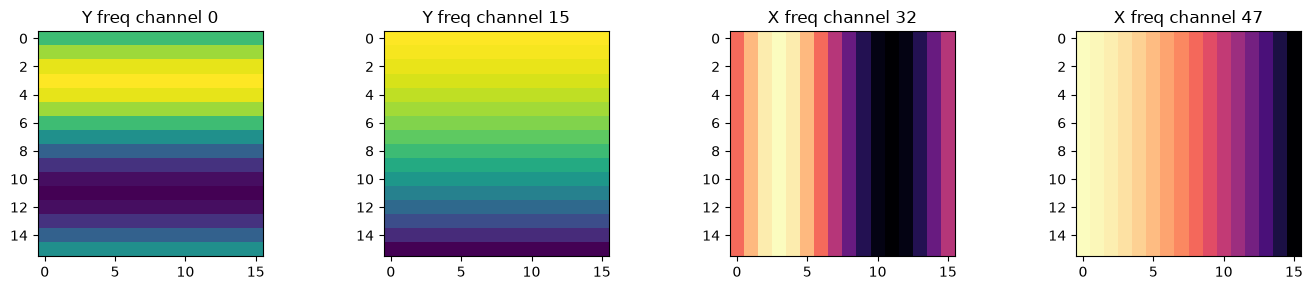

In [3]:
pos_encoder = PositionEmbeddingSine(num_pos_feats=32)  # Output dim = 64
dummy_features = torch.zeros(1, 64, 16, 16)
pos = pos_encoder(dummy_features)

print(f"Position embedding shape: {pos.shape} -> (B, hidden_dim, H, W)")

# Visualize positional pattern across spatial dimensions
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
axes[0].imshow(pos[0, 0].detach().cpu(), cmap="viridis")
axes[0].set_title("Y freq channel 0")
axes[1].imshow(pos[0, 15].detach().cpu(), cmap="viridis")
axes[1].set_title("Y freq channel 15")
axes[2].imshow(pos[0, 32].detach().cpu(), cmap="magma")
axes[2].set_title("X freq channel 32")
axes[3].imshow(pos[0, 47].detach().cpu(), cmap="magma")
axes[3].set_title("X freq channel 47")
plt.tight_layout()
plt.show()

---
## 3. Bipartite Hungarian Matcher
DETR predicts $N$ queries simultaneously. The matcher finds the permutation $\sigma \in \mathfrak{S}_N$ that minimizes the global matching cost with ground-truth objects using the Hungarian algorithm (`scipy.optimize.linear_sum_assignment`).

In [4]:
matcher = HungarianMatcher(cost_class=1.0, cost_bbox=5.0, cost_giou=2.0)

# Synthetic outputs with 4 queries
pred_logits = torch.tensor([[
    [ 3.0, -3.0, -3.0],  # Q0: predicts class 0
    [-3.0,  3.0, -3.0],  # Q1: predicts class 1
    [-3.0, -3.0,  3.0],  # Q2: predicts background
    [ 2.5, -2.5, -2.5],  # Q3: predicts class 0
]])
pred_boxes = torch.tensor([[
    [0.1, 0.1, 0.2, 0.2],
    [0.8, 0.8, 0.2, 0.2],
    [0.5, 0.5, 0.1, 0.1],
    [0.3, 0.3, 0.2, 0.2],
]])

targets = [{
    "labels": torch.tensor([1, 0]),
    "boxes": torch.tensor([[0.8, 0.8, 0.2, 0.2], [0.1, 0.1, 0.2, 0.2]]),
}]

matches = matcher({"pred_logits": pred_logits, "pred_boxes": pred_boxes}, targets)
src_idx, tgt_idx = matches[0]
for s, t in zip(src_idx.tolist(), tgt_idx.tolist()):
    print(f"Target object {t} (Class {targets[0]['labels'][t].item()}) matched with Prediction Query {s}")

Target object 1 (Class 0) matched with Prediction Query 0
Target object 0 (Class 1) matched with Prediction Query 1


---
## 4. End-to-End DETR Training on a Toy Scene
Let's instantiate the complete DETR model and verify that it overfits a toy image with 2 target objects.

Training DETR on single toy image...
Initial loss: 7.7439 -> Final loss: 0.4780


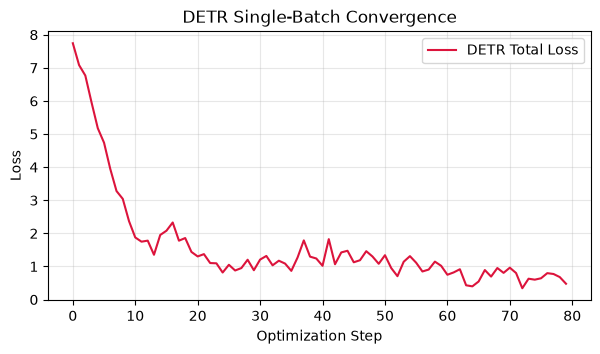

In [5]:
torch.manual_seed(42)

num_classes = 2
num_queries = 6
detr = DETR(num_classes=num_classes, num_queries=num_queries, hidden_dim=64, nheads=2, num_encoder_layers=2, num_decoder_layers=2)
criterion = SetCriterion(num_classes=num_classes, matcher=matcher, weight_dict={"loss_ce": 1.0, "loss_bbox": 5.0, "loss_giou": 2.0})
optimizer = torch.optim.AdamW(detr.parameters(), lr=2e-3, weight_decay=1e-4)

# Synthetic image and 2 target objects
image = torch.randn(1, 3, 32, 32)
gt_targets = [{
    "labels": torch.tensor([0, 1], dtype=torch.int64),
    "boxes": torch.tensor([[0.25, 0.25, 0.3, 0.3], [0.70, 0.70, 0.25, 0.25]]),
}]

losses = []
print("Training DETR on single toy image...")
for step in range(80):
    optimizer.zero_grad()
    out = detr(image)
    loss_dict = criterion(out, gt_targets)
    total_loss = loss_dict["loss_ce"] + 5.0 * loss_dict["loss_bbox"] + 2.0 * loss_dict["loss_giou"]
    total_loss.backward()
    optimizer.step()
    losses.append(total_loss.item())

print(f"Initial loss: {losses[0]:.4f} -> Final loss: {losses[-1]:.4f}")

plt.figure(figsize=(7, 3.5))
plt.plot(losses, label="DETR Total Loss", color="crimson")
plt.xlabel("Optimization Step")
plt.ylabel("Loss")
plt.title("DETR Single-Batch Convergence")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

---
## 5. Visualizing Predicted vs Ground Truth Bounding Boxes

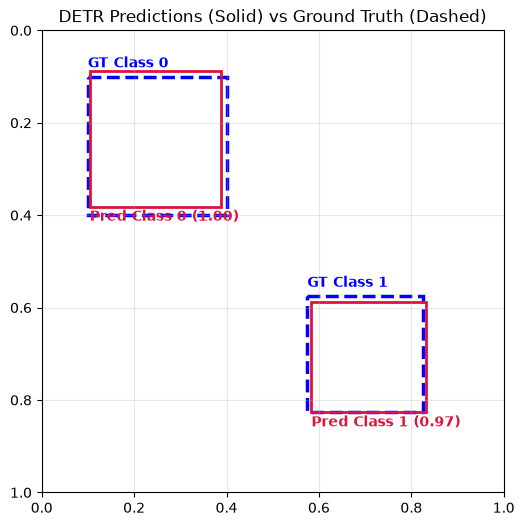

In [6]:
# Inspect final predictions
detr.eval()
with torch.no_grad():
    out = detr(image)
    probs = out["pred_logits"].softmax(-1)[0]  # [num_queries, num_classes + 1]
    boxes = out["pred_boxes"][0]  # [num_queries, 4] in (cx, cy, w, h)

fig, ax = plt.subplots(1, 1, figsize=(6, 6))
ax.set_xlim(0, 1)
ax.set_ylim(1, 0)  # Invert y-axis to match image coordinate system
ax.set_aspect("equal")
ax.set_title("DETR Predictions (Solid) vs Ground Truth (Dashed)")

# Draw ground truth boxes
for box, label in zip(gt_targets[0]["boxes"], gt_targets[0]["labels"]):
    cx, cy, w, h = box.tolist()
    rect = patches.Rectangle((cx - w/2, cy - h/2), w, h, linewidth=2.5, edgecolor="blue", facecolor="none", linestyle="--", label="GT Box" if label == 0 else "")
    ax.add_patch(rect)
    ax.text(cx - w/2, cy - h/2 - 0.02, f"GT Class {label.item()}", color="blue", fontweight="bold")

# Draw predicted boxes with foreground confidence > 0.5
for q_idx in range(num_queries):
    prob = probs[q_idx]
    cls_id = prob[:num_classes].argmax().item()
    confidence = prob[cls_id].item()
    if confidence > 0.4 and prob[-1].item() < 0.6:
        cx, cy, w, h = boxes[q_idx].tolist()
        rect = patches.Rectangle((cx - w/2, cy - h/2), w, h, linewidth=2, edgecolor="crimson", facecolor="none", label="Pred Box")
        ax.add_patch(rect)
        ax.text(cx - w/2, cy + h/2 + 0.03, f"Pred Class {cls_id} ({confidence:.2f})", color="crimson", fontweight="bold")

plt.grid(True, alpha=0.3)
plt.show()